In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import (accuracy_score, classification_report, 
                             confusion_matrix, roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings('ignore')

import random
import os
from sklearn.model_selection import KFold
import ast

# Full reproducibility
seed = 42

np.random.seed(seed)
random.seed(seed)

os.environ["PYTHONHASHSEED"] = str(seed)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

cv = KFold(n_splits=5, shuffle=True, random_state=seed)


In [128]:
# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [129]:
# Use a compatible matplotlib style
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except:
    try:
        plt.style.use('seaborn-whitegrid')
    except:
        plt.style.use('ggplot')  # Fallback style

In [130]:
# Load all three datasets
user_features = pd.read_csv('user_features.csv')
product_features = pd.read_csv('product_features.csv')
click_history = pd.read_csv('click_history.csv')

In [131]:
print(f"\nShape: {user_features.shape[0]} rows × {user_features.shape[1]} columns")


Shape: 12000 rows × 4 columns


In [132]:
print("\n--- Column Information ---")
print(user_features.dtypes)


--- Column Information ---
user_id                     int64
number_of_clicks_before    object
ordered_before               bool
personal_interests         object
dtype: object


In [133]:
print("\n--- First 5 Rows ---")
print(user_features.head())


--- First 5 Rows ---
   user_id number_of_clicks_before  ordered_before  \
0   104939                       2            True   
1   101562                       2            True   
2   102343                       2            True   
3   106728                       5            True   
4   107179                       0            True   

                                  personal_interests  
0  ['body', 'makeup', 'nail', 'hand', 'foot', 'me...  
1  ['men_skincare', 'men_fragrance', 'tools', 'sk...  
2                ['tools', 'makeup', 'foot', 'nail']  
3                           ['hand', 'men_skincare']  
4  ['makeup', 'body', 'skincare', 'foot', 'men_sk...  


In [134]:
print("\n--- Statistical Summary ---")
print(user_features.describe(include='all'))


--- Statistical Summary ---
             user_id number_of_clicks_before ordered_before personal_interests
count    12000.00000                   11500          12000              12000
unique           NaN                       7              2               8316
top              NaN                       2           True                 []
freq             NaN                    2710           8400               1096
mean    105999.50000                     NaN            NaN                NaN
std       3464.24595                     NaN            NaN                NaN
min     100000.00000                     NaN            NaN                NaN
25%     102999.75000                     NaN            NaN                NaN
50%     105999.50000                     NaN            NaN                NaN
75%     108999.25000                     NaN            NaN                NaN
max     111999.00000                     NaN            NaN                NaN


In [135]:
print("\n--- Missing Values ---")
print(user_features.isnull().sum())


--- Missing Values ---
user_id                      0
number_of_clicks_before    500
ordered_before               0
personal_interests           0
dtype: int64


In [136]:
print("\n--- Unique Values per Column ---")
for col in user_features.columns:
    print(f"{col}: {user_features[col].nunique()} unique values")


--- Unique Values per Column ---
user_id: 12000 unique values
number_of_clicks_before: 7 unique values
ordered_before: 2 unique values
personal_interests: 8316 unique values


In [137]:
print("\n--- Value Counts for 'number_of_clicks_before' ---")
print(user_features['number_of_clicks_before'].value_counts())


--- Value Counts for 'number_of_clicks_before' ---
number_of_clicks_before
2     2710
1     2399
6+    2368
0     2196
5     1057
4      711
3       59
Name: count, dtype: int64


In [138]:
print("\n--- Value Counts for 'ordered_before' ---")
print(user_features['ordered_before'].value_counts())


--- Value Counts for 'ordered_before' ---
ordered_before
True     8400
False    3600
Name: count, dtype: int64


In [139]:
print(f"\nShape: {product_features.shape[0]} rows × {product_features.shape[1]} columns")


Shape: 1000 rows × 5 columns


In [140]:
print("\n--- Column Information ---")
print(product_features.dtypes)


--- Column Information ---
product_id             int64
category              object
on_sale                 bool
number_of_reviews      int64
avg_review_score     float64
dtype: object


In [141]:
print("\n--- First 5 Rows ---")
print(product_features.head())


--- First 5 Rows ---
   product_id   category  on_sale  number_of_reviews  avg_review_score
0        1134      tools    False                101          3.349452
1        1846   skincare    False                111          5.000000
2        1762  fragrance    False                220          4.882706
3        1254       hair     True                446          5.000000
4        1493       body     True                513         -1.000000


In [142]:
print("\n--- Statistical Summary ---")
print(product_features.describe())


--- Statistical Summary ---
        product_id  number_of_reviews  avg_review_score
count  1000.000000       1.000000e+03       1000.000000
mean   1499.500000       1.157725e+05          2.660656
std     288.819436       5.028997e+05          1.741875
min    1000.000000       6.600000e+01         -1.000000
25%    1249.750000       2.570000e+02          1.428969
50%    1499.500000       4.710000e+02          2.769397
75%    1749.250000       7.042500e+02          4.180860
max    1999.000000       2.307390e+06          5.000000


In [143]:
print("\n--- Missing Values ---")
print(product_features.isnull().sum())


--- Missing Values ---
product_id           0
category             0
on_sale              0
number_of_reviews    0
avg_review_score     0
dtype: int64


In [144]:
print("\n--- Product Categories Distribution ---")
print(product_features['category'].value_counts())


--- Product Categories Distribution ---
category
makeup           124
foot             120
hair             109
hand             102
men_skincare      98
body              97
skincare          76
men_fragrance     75
nail              72
fragrance         71
tools             56
Name: count, dtype: int64


In [145]:
print("\n--- On Sale Distribution ---")
print(product_features['on_sale'].value_counts())


--- On Sale Distribution ---
on_sale
True     650
False    350
Name: count, dtype: int64


In [146]:
print(f"\nShape: {click_history.shape[0]} rows × {click_history.shape[1]} columns")


Shape: 35990 rows × 3 columns


In [147]:
print("\n--- Column Information ---")
print(click_history.dtypes)


--- Column Information ---
user_id       int64
product_id    int64
clicked        bool
dtype: object


In [148]:
print("\n--- First 5 Rows ---")
print(click_history.head())


--- First 5 Rows ---
   user_id  product_id  clicked
0   104863        1350    False
1   108656        1321     True
2   100120        1110    False
3   104838        1443     True
4   107304        1397     True


In [149]:
print("\n--- Statistical Summary ---")
print(click_history.describe())


--- Statistical Summary ---
             user_id    product_id
count   35990.000000  35990.000000
mean   106017.080161   1500.232898
std      3483.480090    288.101984
min    100001.000000   1000.000000
25%    102976.500000   1250.000000
50%    106060.000000   1503.000000
75%    109049.000000   1749.000000
max    111999.000000   1999.000000


In [150]:
print("\n--- Missing Values ---")
print(click_history.isnull().sum())


--- Missing Values ---
user_id       0
product_id    0
clicked       0
dtype: int64


In [151]:
print("\n--- Target Variable (clicked) Distribution ---")
print(click_history['clicked'].value_counts())
click_rate = click_history['clicked'].sum() / len(click_history) * 100
print(f"\nClick Rate: {click_rate:.2f}%")


--- Target Variable (clicked) Distribution ---
clicked
False    23302
True     12688
Name: count, dtype: int64

Click Rate: 35.25%


In [152]:
# Make sure matplotlib works in Jupyter
%matplotlib inline

In [153]:
# Create figure with subplots
fig = plt.figure(figsize=(16, 11))

In [154]:
# Plot 1: Click Distribution (Target Variable) - Pie Chart
ax1 = fig.add_subplot(3, 2, 1)
click_counts = click_history['clicked'].value_counts()
click_labels = ['No Click', 'Clicked']
click_values = [click_counts.get(False, 0), click_counts.get(True, 0)]
colors = ['#ff6b6b', '#4ecdc4']
ax1.pie(click_values, labels=click_labels, autopct='%1.1f%%', colors=colors, startangle=90)
ax1.set_title('Fig. 1. Target Variable Distribution\n(Clicked vs Not Clicked)')

Text(0.5, 1.0, 'Fig. 1. Target Variable Distribution\n(Clicked vs Not Clicked)')

In [155]:
# Plot 2: Product Categories Distribution - Bar Chart
ax2 = fig.add_subplot(3, 2, 2)
category_counts = product_features['category'].value_counts()
x_pos = np.arange(len(category_counts))
ax2.bar(x_pos, category_counts.values, color='steelblue', edgecolor='black')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(category_counts.index, rotation=45, ha='right', fontsize=9)
ax2.set_title('Fig. 2. Product Categories Distribution')
ax2.set_xlabel('Category')
ax2.set_ylabel('Count')

Text(0, 0.5, 'Count')

In [156]:
# Plot 3: On Sale Distribution - Bar Chart
ax3 = fig.add_subplot(3, 2, 3)
onsale_counts = product_features['on_sale'].value_counts()
sale_labels = ['Not On Sale', 'On Sale']
sale_values = [onsale_counts.get(False, 0), onsale_counts.get(True, 0)]
ax3.bar(sale_labels, sale_values, color=['#ff6b6b', '#4ecdc4'], edgecolor='black')
ax3.set_title('Fig. 3. Products On Sale Distribution')
ax3.set_xlabel('On Sale Status')
ax3.set_ylabel('Count')

Text(0, 0.5, 'Count')

In [157]:
# Plot 4: Number of Reviews Distribution - Histogram
ax4 = fig.add_subplot(3, 2, 4)
review_data = product_features['number_of_reviews'].dropna().values
ax4.hist(review_data, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax4.set_title('Fig. 4. Number of Reviews Distribution')
ax4.set_xlabel('Number of Reviews')
ax4.set_ylabel('Frequency (log scale)')
ax4.set_yscale('log')

In [158]:
# Plot 5: Average Review Score Distribution - Histogram
ax5 = fig.add_subplot(3, 2, 5)
score_data = product_features['avg_review_score'].dropna().values
ax5.hist(score_data, bins=30, color='coral', edgecolor='black', alpha=0.7)
ax5.set_title('Fig. 5. Average Review Score Distribution')
ax5.set_xlabel('Average Review Score')
ax5.set_ylabel('Frequency')

Text(0, 0.5, 'Frequency')

In [159]:
# Plot 6: Ordered Before Distribution - Bar Chart
ax6 = fig.add_subplot(3, 2, 6)
ordered_counts = user_features['ordered_before'].value_counts()
order_labels = ['No', 'Yes']
order_values = [ordered_counts.get(False, 0), ordered_counts.get(True, 0)]
ax6.bar(order_labels, order_values, color=['#ff6b6b', '#4ecdc4'], edgecolor='black')
ax6.set_title('Fig. 6. Users Who Ordered Before')
ax6.set_xlabel('Ordered Before')
ax6.set_ylabel('Count')

Text(0, 0.5, 'Count')

In [160]:
# Add main title
fig.suptitle('Exploratory Data Analysis - Data Understanding', fontsize=14, fontweight='bold', y=1.02)

Text(0.5, 1.02, 'Exploratory Data Analysis - Data Understanding')

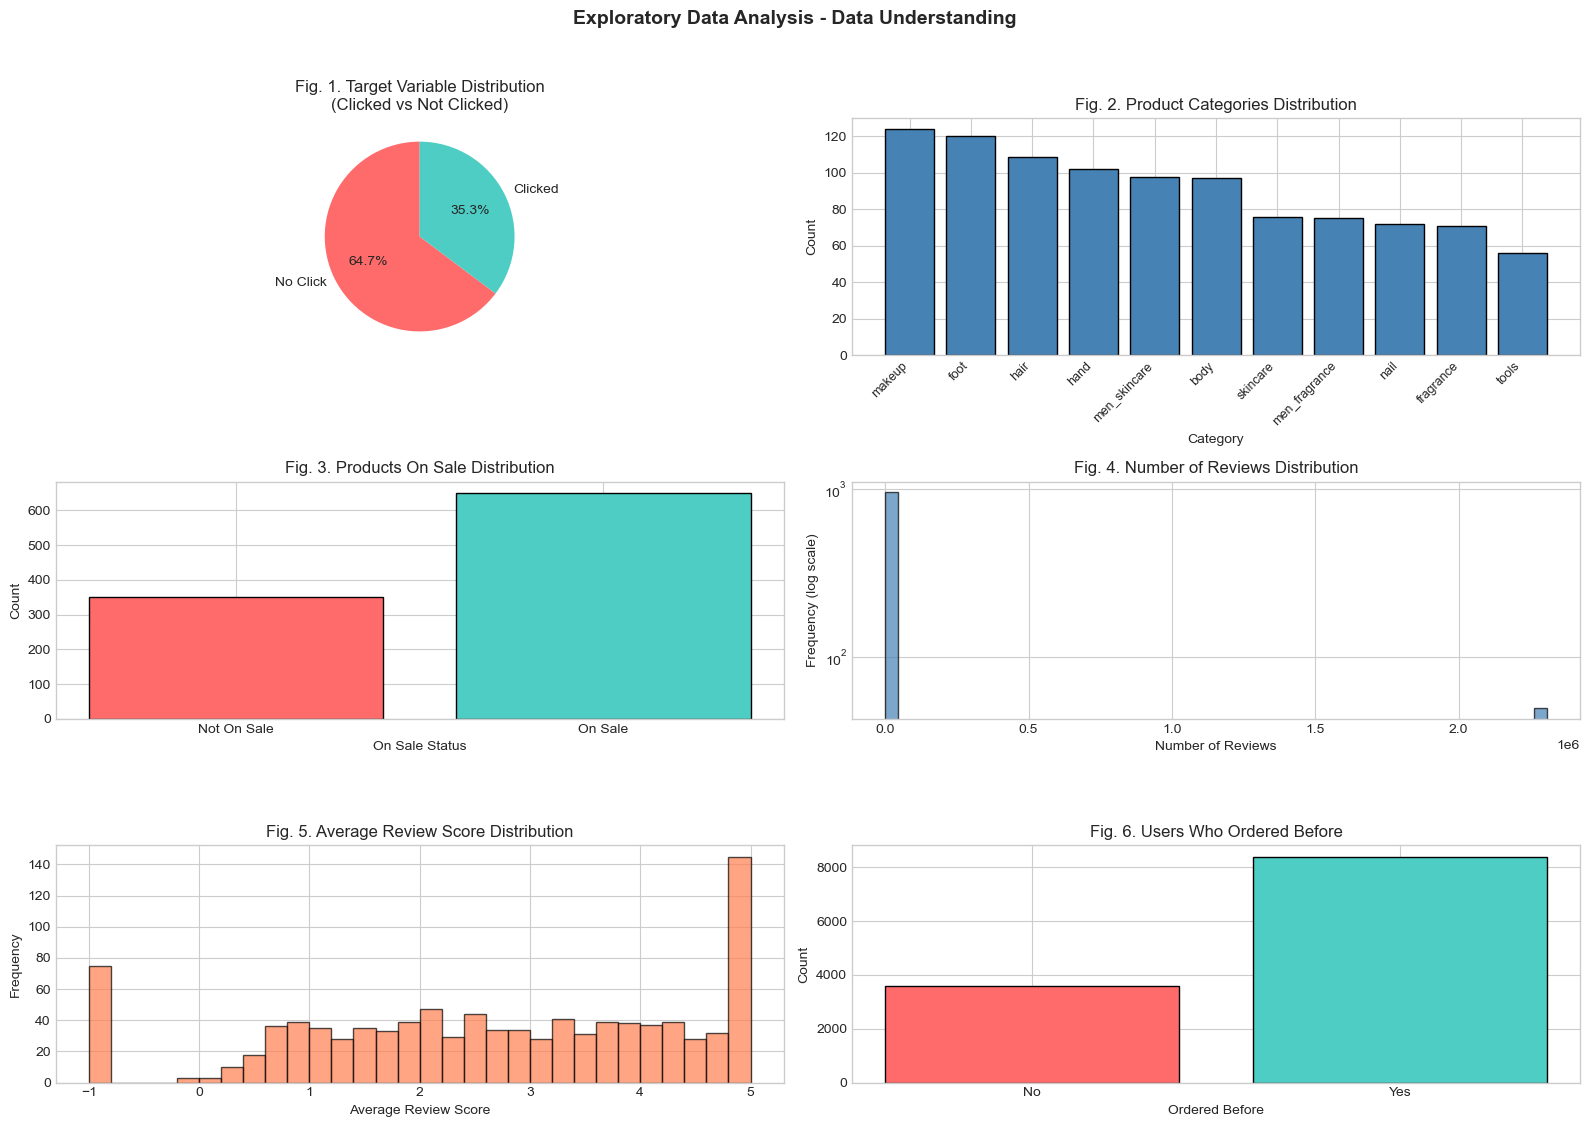

In [161]:
plt.tight_layout()
plt.show()

In [162]:
# Make a copy for cleaning
users_clean = user_features.copy()

In [163]:
# Check missing values
print(f"Missing values before cleaning:")
print(users_clean.isnull().sum())

Missing values before cleaning:
user_id                      0
number_of_clicks_before    500
ordered_before               0
personal_interests           0
dtype: int64


In [164]:
# Handle 'number_of_clicks_before' column
# Convert '6+' to numeric value (6) and handle missing values
print(f"\nUnique values in 'number_of_clicks_before': {users_clean['number_of_clicks_before'].unique()}")


Unique values in 'number_of_clicks_before': ['2' '5' '0' '4' '1' '6+' nan '3']


In [165]:
# Replace '6+' with 6
users_clean['number_of_clicks_before'] = users_clean['number_of_clicks_before'].replace('6+', '6')

In [166]:
# Fill missing values with median (after conversion to numeric)
users_clean['number_of_clicks_before'] = pd.to_numeric(users_clean['number_of_clicks_before'], errors='coerce')
median_clicks = users_clean['number_of_clicks_before'].median()
users_clean['number_of_clicks_before'].fillna(median_clicks, inplace=True)
users_clean['number_of_clicks_before'] = users_clean['number_of_clicks_before'].astype(int)

In [167]:
print(f"\nMissing values after cleaning 'number_of_clicks_before': {users_clean['number_of_clicks_before'].isnull().sum()}")
print(f"Value counts after cleaning:")
print(users_clean['number_of_clicks_before'].value_counts().sort_index())


Missing values after cleaning 'number_of_clicks_before': 0
Value counts after cleaning:
number_of_clicks_before
0    2196
1    2399
2    3210
3      59
4     711
5    1057
6    2368
Name: count, dtype: int64


In [168]:
# Convert 'ordered_before' to binary (0/1)
users_clean['ordered_before'] = users_clean['ordered_before'].astype(int)

In [169]:
# Parse 'personal_interests' and create binary features for each category
print("\n--- Creating Interest Category Features ---")


--- Creating Interest Category Features ---


In [170]:
def parse_interests(x):
    """Parse the string representation of list into actual list"""
    try:
        if pd.isna(x):
            return []
        return ast.literal_eval(x)
    except:
        return []

In [171]:
users_clean['interests_list'] = users_clean['personal_interests'].apply(parse_interests)

In [172]:
# Get all unique interests
all_interests = set()
for interests in users_clean['interests_list']:
    all_interests.update(interests)

In [173]:
print(f"Unique interest categories found: {all_interests}")

Unique interest categories found: {'foot', 'tools', 'nail', 'makeup', 'hair', 'men_skincare', 'body', 'men_fragrance', 'skincare', 'fragrance', 'hand'}


In [174]:
# Create binary columns for each interest
for interest in all_interests:
    users_clean[f'interest_{interest}'] = users_clean['interests_list'].apply(lambda x: 1 if interest in x else 0)

In [175]:
# Count number of interests per user
users_clean['num_interests'] = users_clean['interests_list'].apply(len)

In [176]:
# Drop the original columns we no longer need
users_clean.drop(['personal_interests', 'interests_list'], axis=1, inplace=True)

In [177]:
print(f"\nUser features after cleaning - Shape: {users_clean.shape}")
print(users_clean.head())


User features after cleaning - Shape: (12000, 15)
   user_id  number_of_clicks_before  ordered_before  interest_foot  \
0   104939                        2               1              1   
1   101562                        2               1              0   
2   102343                        2               1              1   
3   106728                        5               1              0   
4   107179                        0               1              1   

   interest_tools  interest_nail  interest_makeup  interest_hair  \
0               1              1                1              1   
1               1              1                1              0   
2               1              1                1              0   
3               0              0                0              0   
4               0              0                1              1   

   interest_men_skincare  interest_body  interest_men_fragrance  \
0                      0              1             

In [178]:
products_clean = product_features.copy()

In [179]:
# Check for missing values
print(f"Missing values in product features:")
print(products_clean.isnull().sum())

Missing values in product features:
product_id           0
category             0
on_sale              0
number_of_reviews    0
avg_review_score     0
dtype: int64


In [180]:
# Handle negative avg_review_score (replace -1 with NaN, then fill with median)
print(f"\nProducts with avg_review_score = -1: {(products_clean['avg_review_score'] == -1).sum()}")
products_clean['avg_review_score'] = products_clean['avg_review_score'].replace(-1, np.nan)
products_clean['avg_review_score'].fillna(products_clean['avg_review_score'].median(), inplace=True)


Products with avg_review_score = -1: 75


In [181]:
# Handle outliers in number_of_reviews using IQR method
Q1 = products_clean['number_of_reviews'].quantile(0.25)
Q3 = products_clean['number_of_reviews'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

In [182]:
print(f"\nNumber of reviews - Q1: {Q1}, Q3: {Q3}, IQR: {IQR}, Upper bound: {upper_bound}")
outliers_count = (products_clean['number_of_reviews'] > upper_bound).sum()
print(f"Outliers in number_of_reviews: {outliers_count}")


Number of reviews - Q1: 257.0, Q3: 704.25, IQR: 447.25, Upper bound: 1375.125
Outliers in number_of_reviews: 50


In [183]:
# Cap outliers at upper bound
products_clean['number_of_reviews'] = products_clean['number_of_reviews'].clip(upper=upper_bound)

In [184]:
# Convert 'on_sale' to binary
products_clean['on_sale'] = products_clean['on_sale'].astype(int)

In [185]:
# Create dummy variables for 'category'
print("\n--- Creating Category Dummy Variables ---")
category_dummies = pd.get_dummies(products_clean['category'], prefix='cat')
products_clean = pd.concat([products_clean, category_dummies], axis=1)
products_clean.drop('category', axis=1, inplace=True)


--- Creating Category Dummy Variables ---


In [186]:
print(f"\nProduct features after cleaning - Shape: {products_clean.shape}")
print(products_clean.head())


Product features after cleaning - Shape: (1000, 15)
   product_id  on_sale  number_of_reviews  avg_review_score  cat_body  \
0        1134        0              101.0          3.349452     False   
1        1846        0              111.0          5.000000     False   
2        1762        0              220.0          4.882706     False   
3        1254        1              446.0          5.000000     False   
4        1493        1              513.0          2.971874      True   

   cat_foot  cat_fragrance  cat_hair  cat_hand  cat_makeup  cat_men_fragrance  \
0     False          False     False     False       False              False   
1     False          False     False     False       False              False   
2     False           True     False     False       False              False   
3     False          False      True     False       False              False   
4     False          False     False     False       False              False   

   cat_men_skincare  

In [187]:
clicks_clean = click_history.copy()

In [188]:
# Check for missing values
print(f"Missing values in click history:")
print(clicks_clean.isnull().sum())

Missing values in click history:
user_id       0
product_id    0
clicked       0
dtype: int64


In [189]:
# Convert 'clicked' to binary (target variable)
clicks_clean['clicked'] = clicks_clean['clicked'].astype(int)

In [190]:
print(f"\nClick history after cleaning - Shape: {clicks_clean.shape}")
print(f"Target distribution:")
print(clicks_clean['clicked'].value_counts())


Click history after cleaning - Shape: (35990, 3)
Target distribution:
clicked
0    23302
1    12688
Name: count, dtype: int64


In [191]:
# First, merge clicks with users
merged_data = clicks_clean.merge(users_clean, on='user_id', how='left')
print(f"After merging with users: {merged_data.shape}")

After merging with users: (35990, 17)


In [192]:
# Then, merge with products
merged_data = merged_data.merge(products_clean, on='product_id', how='left')
print(f"After merging with products: {merged_data.shape}")

After merging with products: (35990, 31)


In [193]:
# Check for any missing values after merge
print(f"\nMissing values after merging:")
print(merged_data.isnull().sum())


Missing values after merging:
user_id                    0
product_id                 0
clicked                    0
number_of_clicks_before    0
ordered_before             0
interest_foot              0
interest_tools             0
interest_nail              0
interest_makeup            0
interest_hair              0
interest_men_skincare      0
interest_body              0
interest_men_fragrance     0
interest_skincare          0
interest_fragrance         0
interest_hand              0
num_interests              0
on_sale                    0
number_of_reviews          0
avg_review_score           0
cat_body                   0
cat_foot                   0
cat_fragrance              0
cat_hair                   0
cat_hand                   0
cat_makeup                 0
cat_men_fragrance          0
cat_men_skincare           0
cat_nail                   0
cat_skincare               0
cat_tools                  0
dtype: int64


In [194]:
# Fill any remaining missing values (if any)
merged_data.fillna(merged_data.median(numeric_only=True), inplace=True)

In [195]:
print(f"\nFinal merged dataset shape: {merged_data.shape}")
print(f"\nColumn names in final dataset:")
print(merged_data.columns.tolist())


Final merged dataset shape: (35990, 31)

Column names in final dataset:
['user_id', 'product_id', 'clicked', 'number_of_clicks_before', 'ordered_before', 'interest_foot', 'interest_tools', 'interest_nail', 'interest_makeup', 'interest_hair', 'interest_men_skincare', 'interest_body', 'interest_men_fragrance', 'interest_skincare', 'interest_fragrance', 'interest_hand', 'num_interests', 'on_sale', 'number_of_reviews', 'avg_review_score', 'cat_body', 'cat_foot', 'cat_fragrance', 'cat_hair', 'cat_hand', 'cat_makeup', 'cat_men_fragrance', 'cat_men_skincare', 'cat_nail', 'cat_skincare', 'cat_tools']


In [196]:
# Create interaction features
# Check if product category matches user interest
category_columns = [col for col in merged_data.columns if col.startswith('cat_')]
interest_columns = [col for col in merged_data.columns if col.startswith('interest_')]

In [197]:
# Create a feature indicating if product category matches any user interest
def check_interest_match(row):
    for cat_col in category_columns:
        if row[cat_col] == 1:
            category = cat_col.replace('cat_', '')
            interest_col = f'interest_{category}'
            if interest_col in row.index and row[interest_col] == 1:
                return 1
    return 0

In [198]:
merged_data['category_interest_match'] = merged_data.apply(check_interest_match, axis=1)
print(f"Category-Interest match distribution:")
print(merged_data['category_interest_match'].value_counts())

Category-Interest match distribution:
category_interest_match
0    19754
1    16236
Name: count, dtype: int64


In [199]:
print(f"\nDataset Shape: {merged_data.shape}")
print(f"\nTarget Variable Distribution:")
print(merged_data['clicked'].value_counts())
print(f"\nClass Balance: {merged_data['clicked'].mean()*100:.2f}% positive (clicked)")


Dataset Shape: (35990, 32)

Target Variable Distribution:
clicked
0    23302
1    12688
Name: count, dtype: int64

Class Balance: 35.25% positive (clicked)


In [200]:
print(f"\nData Types:")
print(merged_data.dtypes.value_counts())


Data Types:
int64      19
bool       11
float64     2
Name: count, dtype: int64


In [201]:
print(f"\nFirst 5 rows of final dataset:")
print(merged_data.head())


First 5 rows of final dataset:
   user_id  product_id  clicked  number_of_clicks_before  ordered_before  \
0   104863        1350        0                        2               1   
1   108656        1321        1                        1               1   
2   100120        1110        0                        0               1   
3   104838        1443        1                        0               1   
4   107304        1397        1                        5               1   

   interest_foot  interest_tools  interest_nail  interest_makeup  \
0              0               0              0                0   
1              0               1              1                1   
2              1               1              1                1   
3              1               1              0                1   
4              1               0              0                0   

   interest_hair  interest_men_skincare  interest_body  \
0              1                      0     

In [202]:
# Correlation Analysis
print("\n--- Correlation with Target Variable ---")
numeric_cols = merged_data.select_dtypes(include=[np.number]).columns
correlations = merged_data[numeric_cols].corr()['clicked'].drop('clicked').sort_values(ascending=False)
print("\nTop 10 Positive Correlations with 'clicked':")
print(correlations.head(10))
print("\nTop 10 Negative Correlations with 'clicked':")
print(correlations.tail(10))


--- Correlation with Target Variable ---

Top 10 Positive Correlations with 'clicked':
ordered_before             0.132389
on_sale                    0.120746
category_interest_match    0.052141
num_interests              0.043928
interest_nail              0.031862
interest_tools             0.031248
interest_fragrance         0.030311
interest_men_skincare      0.027996
interest_hand              0.027889
interest_men_fragrance     0.027421
Name: clicked, dtype: float64

Top 10 Negative Correlations with 'clicked':
interest_body              0.025739
interest_makeup            0.022078
interest_foot              0.019162
number_of_clicks_before    0.017115
product_id                 0.016806
interest_skincare          0.016681
interest_hair              0.015888
user_id                    0.011316
avg_review_score          -0.021522
number_of_reviews         -0.105763
Name: clicked, dtype: float64


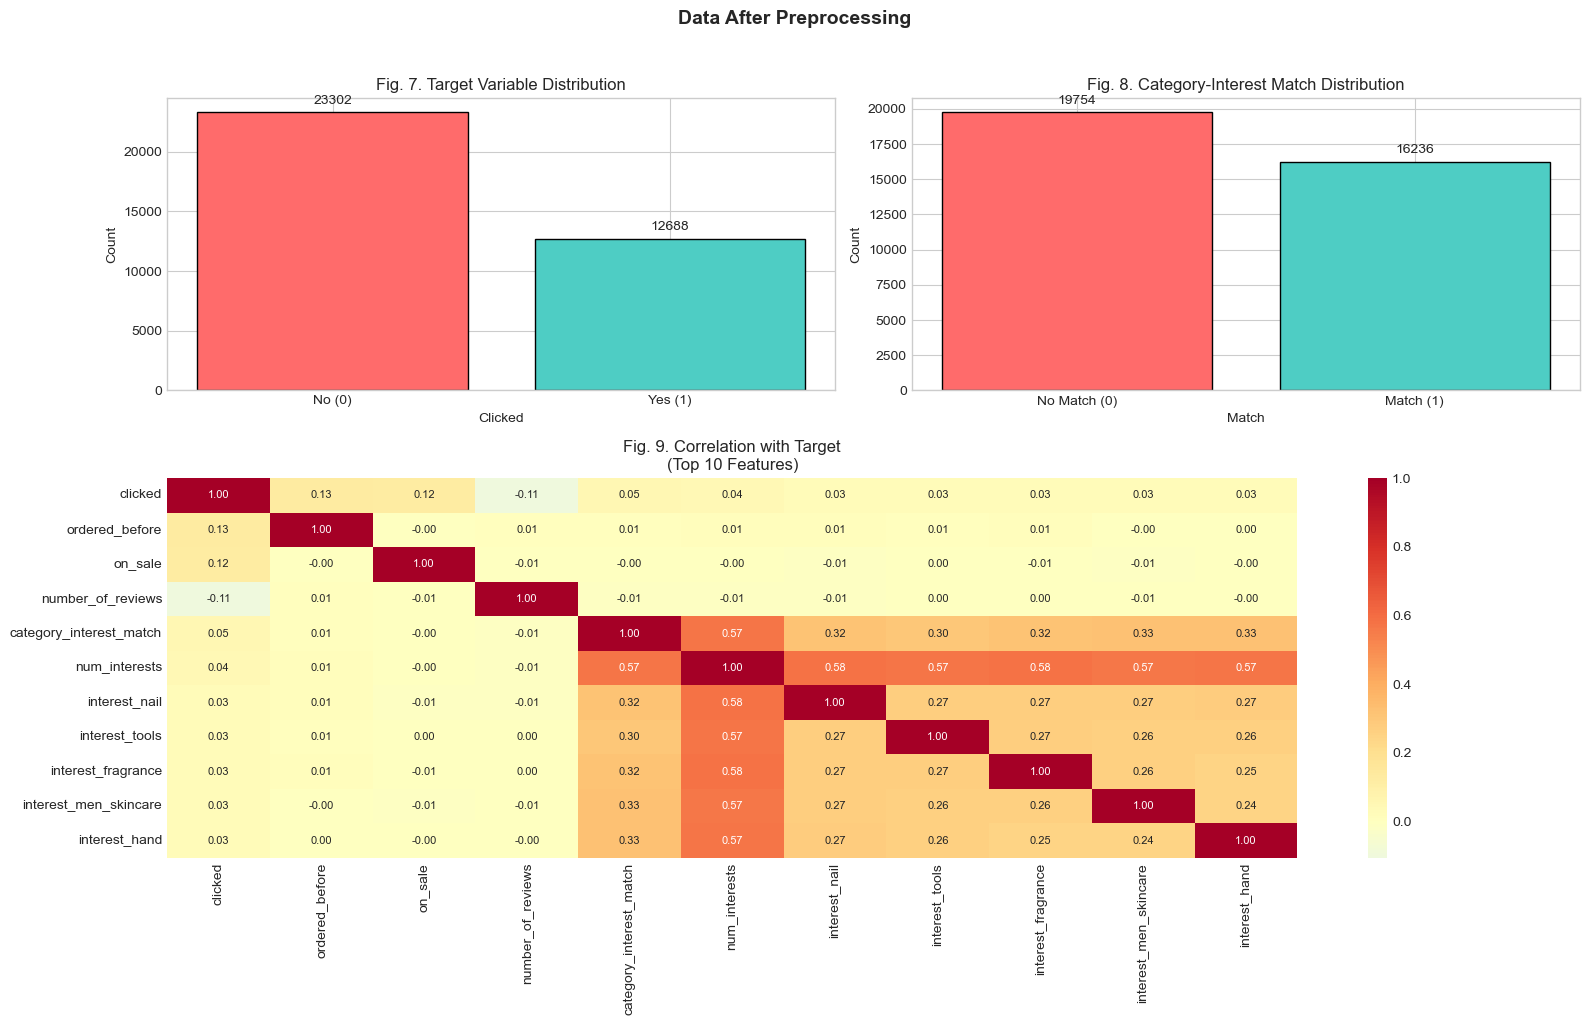

In [203]:
fig = plt.figure(figsize=(16, 10))

# 2x2 grid: first row = 2 plots, second row = heatmap across both columns
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3])

# Plot 1: Target variable distribution (top-left)
ax1 = fig.add_subplot(gs[0, 0])
target_counts = merged_data['clicked'].value_counts()
target_labels = ['No (0)', 'Yes (1)']
target_values = [target_counts.get(0, 0), target_counts.get(1, 0)]

ax1.bar(target_labels, target_values,
        color=['#ff6b6b', '#4ecdc4'], edgecolor='black')
ax1.set_title('Fig. 7. Target Variable Distribution')
ax1.set_xlabel('Clicked')
ax1.set_ylabel('Count')

for i, v in enumerate(target_values):
    ax1.text(i, v + max(target_values) * 0.02, str(v),
             ha='center', va='bottom', fontsize=10)

# Plot 2: Category-Interest Match (top-right)
ax2 = fig.add_subplot(gs[0, 1])
match_counts = merged_data['category_interest_match'].value_counts()
match_labels = ['No Match (0)', 'Match (1)']
match_values = [match_counts.get(0, 0), match_counts.get(1, 0)]

ax2.bar(match_labels, match_values,
        color=['#ff6b6b', '#4ecdc4'], edgecolor='black')
ax2.set_title('Fig. 8. Category-Interest Match Distribution')
ax2.set_xlabel('Match')
ax2.set_ylabel('Count')

for i, v in enumerate(match_values):
    ax2.text(i, v + max(match_values) * 0.02, str(v),
             ha='center', va='bottom', fontsize=10)

# Plot 3: Correlation Heatmap (full-width bottom row)
ax3 = fig.add_subplot(gs[1, :])  # span both columns
top_features = correlations.abs().nlargest(10).index.tolist()
corr_matrix = merged_data[['clicked'] + top_features].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='RdYlBu_r',
    center=0,
    ax=ax3,
    fmt='.2f',
    annot_kws={'size': 8}
)
ax3.set_title('Fig. 9. Correlation with Target\n(Top 10 Features)')

fig.suptitle('Data After Preprocessing',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [204]:
# Define features (X) and target (y)
# Exclude non-feature columns
exclude_cols = ['user_id', 'product_id', 'clicked']
feature_cols = [col for col in merged_data.columns if col not in exclude_cols]

In [205]:
X = merged_data[feature_cols]
y = merged_data['clicked']

In [206]:
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nFeatures used for modeling:")
print(feature_cols)

Features shape: (35990, 29)
Target shape: (35990,)

Features used for modeling:
['number_of_clicks_before', 'ordered_before', 'interest_foot', 'interest_tools', 'interest_nail', 'interest_makeup', 'interest_hair', 'interest_men_skincare', 'interest_body', 'interest_men_fragrance', 'interest_skincare', 'interest_fragrance', 'interest_hand', 'num_interests', 'on_sale', 'number_of_reviews', 'avg_review_score', 'cat_body', 'cat_foot', 'cat_fragrance', 'cat_hair', 'cat_hand', 'cat_makeup', 'cat_men_fragrance', 'cat_men_skincare', 'cat_nail', 'cat_skincare', 'cat_tools', 'category_interest_match']


In [207]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=seed, shuffle=True
)


In [208]:
print(f"\nTraining set size: {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set size: {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\nTraining target distribution:")
print(y_train.value_counts())
print(f"\nTest target distribution:")
print(y_test.value_counts())


Training set size: 25193 (70.0%)
Test set size: 10797 (30.0%)

Training target distribution:
clicked
0    16310
1     8883
Name: count, dtype: int64

Test target distribution:
clicked
0    6992
1    3805
Name: count, dtype: int64


In [209]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [210]:
print("\nFeatures scaled using MinMaxScaler for Neural Network")


Features scaled using MinMaxScaler for Neural Network


In [211]:
# Dictionary to store results
results = {}

In [212]:
def evaluate_model(model_name, y_true, y_pred, y_prob=None):
    """Comprehensive model evaluation"""
    accuracy = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, output_dict=True)
    
    results[model_name] = {
        'accuracy': accuracy,
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'f1_score': report['1']['f1-score'],
        'confusion_matrix': cm
    }
    
    if y_prob is not None:
        results[model_name]['auc_roc'] = roc_auc_score(y_true, y_prob)
    
    print(f"\n{'='*50}")
    print(f"{model_name} Results")
    print(f"{'='*50}")
    print(f"Accuracy: {accuracy:.4f}")
    if y_prob is not None:
        print(f"AUC-ROC: {results[model_name]['auc_roc']:.4f}")
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred))
    print(f"\nConfusion Matrix:")
    print(cm)
    
    return results[model_name]

In [213]:
# Basic Logistic Regression
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [214]:
# Predictions
lr_train_pred = lr.predict(X_train)
lr_test_pred = lr.predict(X_test)
lr_test_prob = lr.predict_proba(X_test)[:, 1]

In [215]:
print("\n--- Training Performance ---")
print(f"Training Accuracy: {accuracy_score(y_train, lr_train_pred):.4f}")


--- Training Performance ---
Training Accuracy: 0.6467


In [216]:
print("\n--- Test Performance ---")
lr_results = evaluate_model('Logistic Regression', y_test, lr_test_pred, lr_test_prob)


--- Test Performance ---

Logistic Regression Results
Accuracy: 0.6440
AUC-ROC: 0.6384

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.93      0.77      6992
           1       0.48      0.13      0.20      3805

    accuracy                           0.64     10797
   macro avg       0.57      0.53      0.49     10797
weighted avg       0.60      0.64      0.57     10797


Confusion Matrix:
[[6470  522]
 [3322  483]]


In [217]:
# Hyperparameter Tuning for Logistic Regression
print("\n--- Hyperparameter Tuning ---")
lr_params = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}


--- Hyperparameter Tuning ---


In [218]:
lr_grid = GridSearchCV(
    LogisticRegression(random_state=seed, max_iter=1000),
    lr_params,
    cv=cv,                    
    scoring='accuracy',
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(max_iter=1000, random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10], 'penalty': ['l1', 'l2'],
                         'solver': ['liblinear']},
             scoring='accuracy')

In [219]:
print(f"Best Parameters: {lr_grid.best_params_}")
print(f"Best CV Score: {lr_grid.best_score_:.4f}")

Best Parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV Score: 0.6452


In [220]:
# Optimized model predictions
lr_opt_pred = lr_grid.predict(X_test)
lr_opt_prob = lr_grid.predict_proba(X_test)[:, 1]
lr_opt_results = evaluate_model('Logistic Regression (Optimized)', y_test, lr_opt_pred, lr_opt_prob)


Logistic Regression (Optimized) Results
Accuracy: 0.6433
AUC-ROC: 0.6384

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.92      0.77      6992
           1       0.48      0.13      0.20      3805

    accuracy                           0.64     10797
   macro avg       0.57      0.53      0.49     10797
weighted avg       0.60      0.64      0.57     10797


Confusion Matrix:
[[6460  532]
 [3319  486]]


In [221]:
# Feature Importance for Logistic Regression
lr_importance = pd.DataFrame({
    'feature': feature_cols,
    'coefficient': lr_grid.best_estimator_.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)
print("\n--- Top 10 Important Features (by coefficient magnitude) ---")
print(lr_importance.head(10))


--- Top 10 Important Features (by coefficient magnitude) ---
                    feature  coefficient
27                cat_tools    -1.078142
25                 cat_nail    -1.070645
19            cat_fragrance    -1.008809
26             cat_skincare    -0.852242
1            ordered_before     0.657843
23        cat_men_fragrance    -0.656418
17                 cat_body    -0.420312
21                 cat_hand    -0.355170
20                 cat_hair    -0.283257
28  category_interest_match     0.182028


In [222]:
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

In [223]:
# Predictions
nb_train_pred = nb.predict(X_train)
nb_test_pred = nb.predict(X_test)
nb_test_prob = nb.predict_proba(X_test)[:, 1]

In [224]:
print("\n--- Training Performance ---")
print(f"Training Accuracy: {accuracy_score(y_train, nb_train_pred):.4f}")


--- Training Performance ---
Training Accuracy: 0.5834


In [225]:
print("\n--- Test Performance ---")
nb_results = evaluate_model('Naive Bayes', y_test, nb_test_pred, nb_test_prob)


--- Test Performance ---

Naive Bayes Results
Accuracy: 0.5795
AUC-ROC: 0.6182

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.57      0.64      6992
           1       0.43      0.60      0.50      3805

    accuracy                           0.58     10797
   macro avg       0.58      0.59      0.57     10797
weighted avg       0.62      0.58      0.59     10797


Confusion Matrix:
[[3956 3036]
 [1504 2301]]


In [226]:
# Basic Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [227]:
# Predictions
dt_train_pred = dt.predict(X_train)
dt_test_pred = dt.predict(X_test)
dt_test_prob = dt.predict_proba(X_test)[:, 1]

In [228]:
print("\n--- Training Performance ---")
print(f"Training Accuracy: {accuracy_score(y_train, dt_train_pred):.4f}")


--- Training Performance ---
Training Accuracy: 0.9965


In [229]:
print("\n--- Test Performance ---")
dt_results = evaluate_model('Decision Tree', y_test, dt_test_pred, dt_test_prob)


--- Test Performance ---

Decision Tree Results
Accuracy: 0.6733
AUC-ROC: 0.6416

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75      6992
           1       0.54      0.53      0.53      3805

    accuracy                           0.67     10797
   macro avg       0.64      0.64      0.64     10797
weighted avg       0.67      0.67      0.67     10797


Confusion Matrix:
[[5242 1750]
 [1777 2028]]


In [230]:
# Hyperparameter Tuning for Decision Tree
print("\n--- Hyperparameter Tuning ---")
dt_params = {
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}


--- Hyperparameter Tuning ---


In [231]:
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=seed),
    dt_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10, 15],
                         'min_samples_leaf': [1, 2, 5, 10],
                         'min_samples_split': [2, 5, 10, 20]},
             scoring='accuracy')

In [232]:
print(f"Best Parameters: {dt_grid.best_params_}")
print(f"Best CV Score: {dt_grid.best_score_:.4f}")

Best Parameters: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV Score: 0.7514


In [233]:
# Optimized model predictions
dt_opt_pred = dt_grid.predict(X_test)
dt_opt_prob = dt_grid.predict_proba(X_test)[:, 1]
dt_opt_results = evaluate_model('Decision Tree (Optimized)', y_test, dt_opt_pred, dt_opt_prob)


Decision Tree (Optimized) Results
Accuracy: 0.7552
AUC-ROC: 0.8084

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.82      6992
           1       0.67      0.61      0.64      3805

    accuracy                           0.76     10797
   macro avg       0.73      0.72      0.73     10797
weighted avg       0.75      0.76      0.75     10797


Confusion Matrix:
[[5823 1169]
 [1474 2331]]


In [234]:
# Feature Importance for Decision Tree
dt_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': dt_grid.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False)
print("\n--- Top 10 Important Features ---")
print(dt_importance.head(10))


--- Top 10 Important Features ---
                    feature  importance
15        number_of_reviews    0.846915
1            ordered_before    0.063939
16         avg_review_score    0.030064
13            num_interests    0.017004
14                  on_sale    0.010062
17                 cat_body    0.006344
24         cat_men_skincare    0.004413
23        cat_men_fragrance    0.004349
28  category_interest_match    0.002674
7     interest_men_skincare    0.002151


In [235]:
# Basic MLP
nn = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=500,
    random_state=seed,
    early_stopping=True,
    validation_fraction=0.1,
    shuffle=False,   
)

nn.fit(X_train_scaled, y_train)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(100, 50), max_iter=500,
              random_state=42, shuffle=False)

In [236]:
# Predictions
nn_train_pred = nn.predict(X_train_scaled)
nn_test_pred = nn.predict(X_test_scaled)
nn_test_prob = nn.predict_proba(X_test_scaled)[:, 1]

In [237]:
print("\n--- Training Performance ---")
print(f"Training Accuracy: {accuracy_score(y_train, nn_train_pred):.4f}")


--- Training Performance ---
Training Accuracy: 0.7714


In [238]:
print("\n--- Test Performance ---")
nn_results = evaluate_model('Neural Network', y_test, nn_test_pred, nn_test_prob)


--- Test Performance ---

Neural Network Results
Accuracy: 0.7504
AUC-ROC: 0.8095

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81      6992
           1       0.66      0.61      0.63      3805

    accuracy                           0.75     10797
   macro avg       0.73      0.72      0.72     10797
weighted avg       0.75      0.75      0.75     10797


Confusion Matrix:
[[5765 1227]
 [1468 2337]]


In [239]:
# Hyperparameter Tuning for Neural Network
print("\n--- Hyperparameter Tuning ---")
nn_params = {
    'hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50)],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['constant', 'adaptive']
}


--- Hyperparameter Tuning ---


In [240]:
nn_grid = GridSearchCV(
    MLPClassifier(
        max_iter=500,
        random_state=seed,
        early_stopping=True,
        validation_fraction=0.1,
        shuffle=False        
    ),
    nn_params,
    cv=cv,                    
    scoring='accuracy',
    n_jobs=-1
)

nn_grid.fit(X_train_scaled, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=MLPClassifier(early_stopping=True, max_iter=500,
                                     random_state=42, shuffle=False),
             n_jobs=-1,
             param_grid={'alpha': [0.0001, 0.001, 0.01],
                         'hidden_layer_sizes': [(50,), (100,), (50, 25),
                                                (100, 50)],
                         'learning_rate': ['constant', 'adaptive']},
             scoring='accuracy')

In [241]:
print(f"Best Parameters: {nn_grid.best_params_}")
print(f"Best CV Score: {nn_grid.best_score_:.4f}")

Best Parameters: {'alpha': 0.0001, 'hidden_layer_sizes': (100, 50), 'learning_rate': 'constant'}
Best CV Score: 0.7489


In [242]:
# Optimized model predictions
nn_opt_pred = nn_grid.predict(X_test_scaled)
nn_opt_prob = nn_grid.predict_proba(X_test_scaled)[:, 1]
nn_opt_results = evaluate_model('Neural Network (Optimized)', y_test, nn_opt_pred, nn_opt_prob)


Neural Network (Optimized) Results
Accuracy: 0.7504
AUC-ROC: 0.8095

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81      6992
           1       0.66      0.61      0.63      3805

    accuracy                           0.75     10797
   macro avg       0.73      0.72      0.72     10797
weighted avg       0.75      0.75      0.75     10797


Confusion Matrix:
[[5765 1227]
 [1468 2337]]


In [243]:
# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results.keys()],
    'Precision': [results[m]['precision'] for m in results.keys()],
    'Recall': [results[m]['recall'] for m in results.keys()],
    'F1-Score': [results[m]['f1_score'] for m in results.keys()],
    'AUC-ROC': [results[m].get('auc_roc', 'N/A') for m in results.keys()]
})

In [244]:
comparison_df = comparison_df.sort_values('Accuracy', ascending=False)
print("\n" + comparison_df.to_string(index=False))


                          Model  Accuracy  Precision   Recall  F1-Score  AUC-ROC
      Decision Tree (Optimized)  0.755210   0.666000 0.612615  0.638193 0.808354
                 Neural Network  0.750394   0.655724 0.614192  0.634279 0.809470
     Neural Network (Optimized)  0.750394   0.655724 0.614192  0.634279 0.809470
                  Decision Tree  0.673335   0.536792 0.532983  0.534881 0.641566
            Logistic Regression  0.643975   0.480597 0.126938  0.200832 0.638357
Logistic Regression (Optimized)  0.643327   0.477407 0.127727  0.201534 0.638443
                    Naive Bayes  0.579513   0.431141 0.604731  0.503391 0.618178


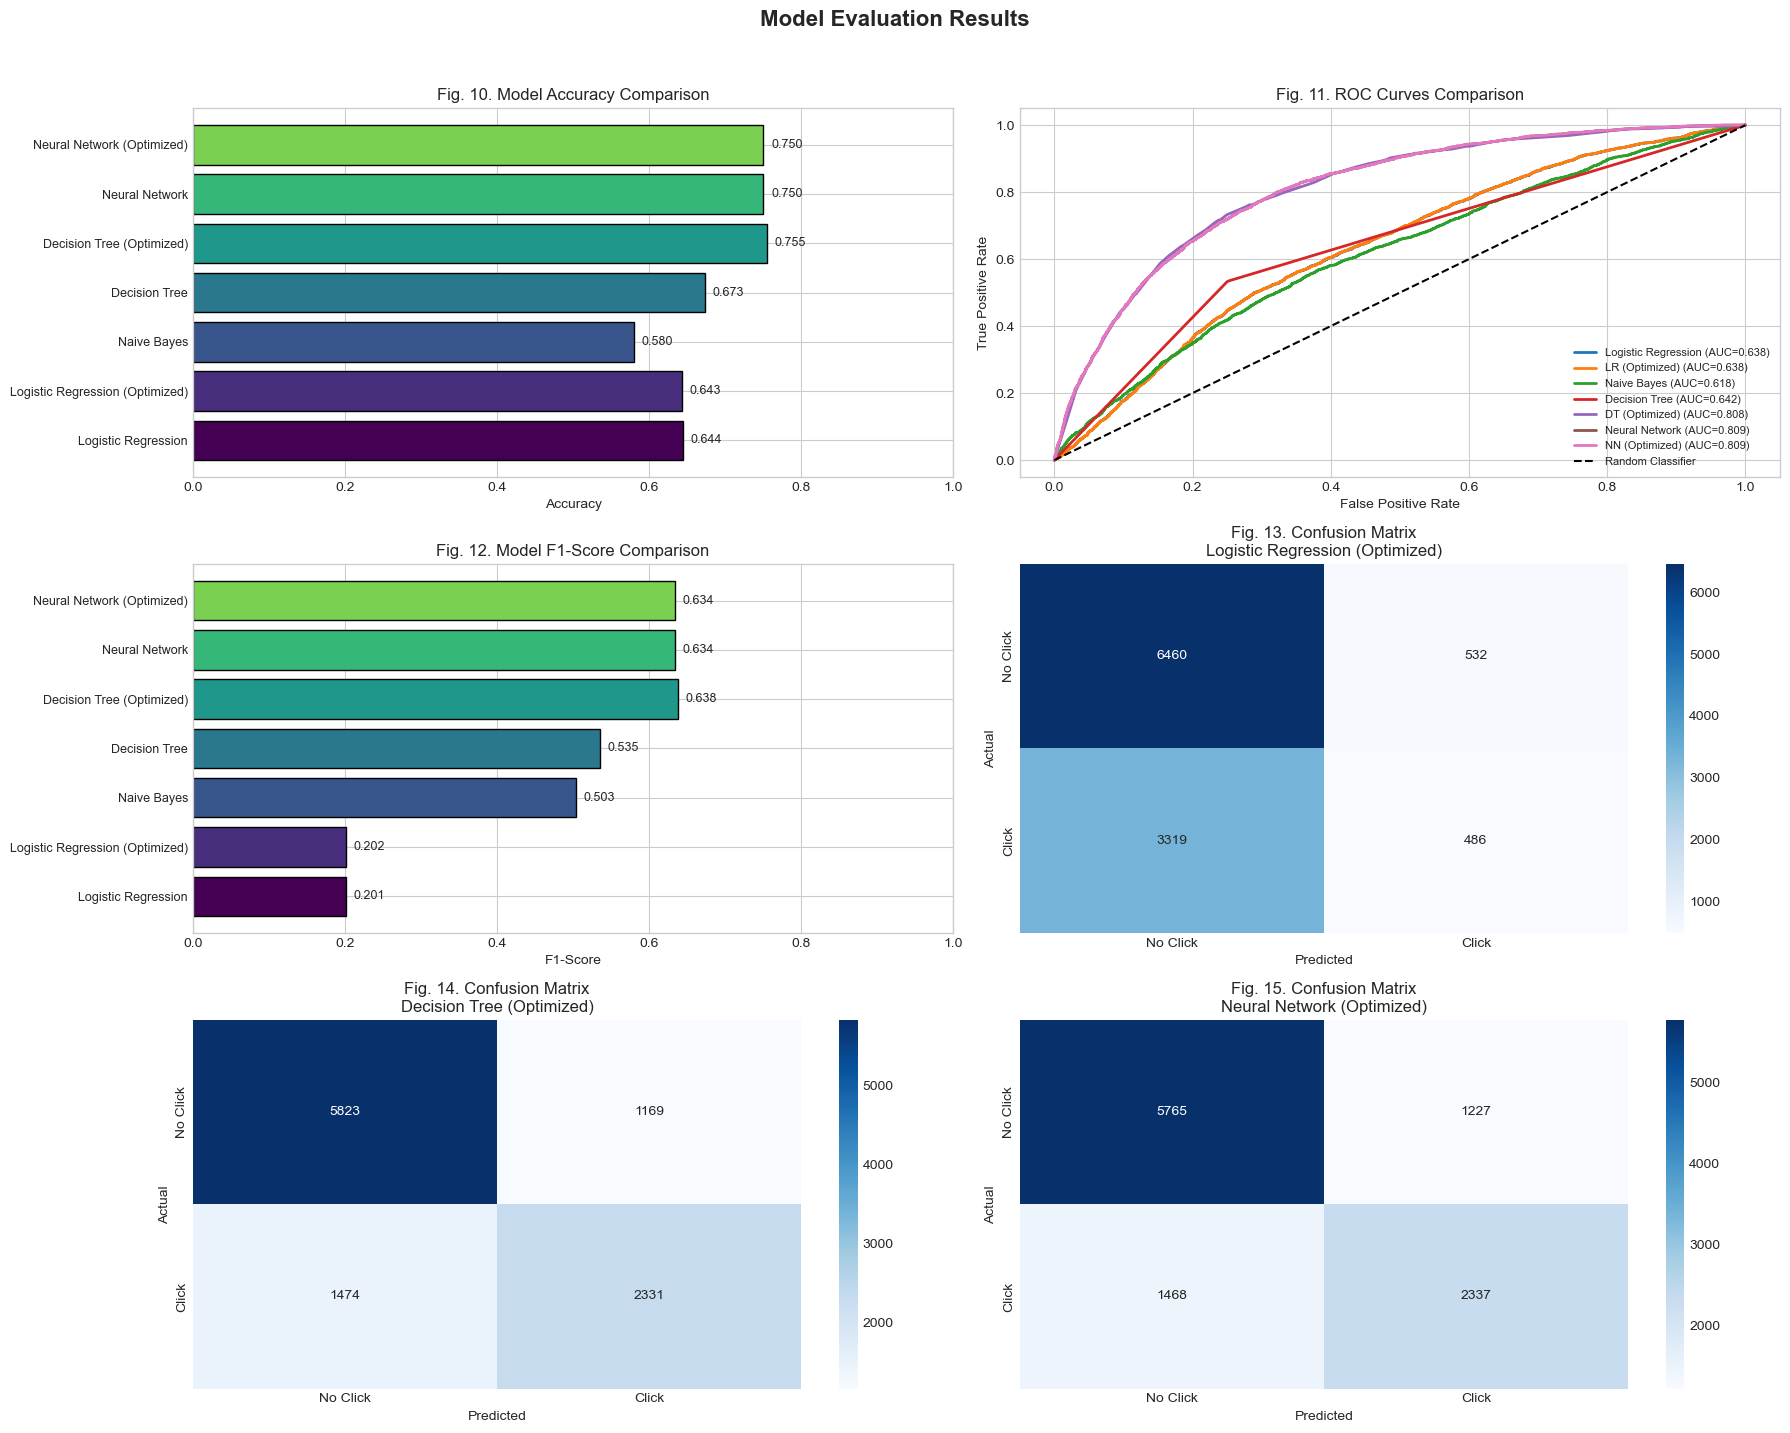

In [245]:
# Close any previously open figures so we only see this one from this cell
plt.close('all')

fig = plt.figure(figsize=(18, 14))

# 3 rows x 2 columns: two charts per row
# Positions are numbered:
# 1 2
# 3 4
# 5 6

# Plot 1: Accuracy Comparison (row 1, col 1)
ax1 = fig.add_subplot(3, 2, 1)
models = list(results.keys())
accuracies = [results[m]['accuracy'] for m in models]
y_pos = np.arange(len(models))
colors = plt.cm.viridis(np.linspace(0, 0.8, len(models)))

bars = ax1.barh(y_pos, accuracies, color=colors, edgecolor='black')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(models, fontsize=9)
ax1.set_xlabel('Accuracy')
ax1.set_title('Fig. 10. Model Accuracy Comparison')
ax1.set_xlim(0, 1)
for i, (bar, acc) in enumerate(zip(bars, accuracies)):
    ax1.text(acc + 0.01, i, f'{acc:.3f}', va='center', fontsize=9)

# Plot 2: ROC Curves (row 1, col 2)
ax2 = fig.add_subplot(3, 2, 2)
model_probs = {
    'Logistic Regression': lr_test_prob,
    'LR (Optimized)': lr_opt_prob,
    'Naive Bayes': nb_test_prob,
    'Decision Tree': dt_test_prob,
    'DT (Optimized)': dt_opt_prob,
    'Neural Network': nn_test_prob,
    'NN (Optimized)': nn_opt_prob
}
for name, prob in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax2.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', linewidth=2)

ax2.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Fig. 11. ROC Curves Comparison')
ax2.legend(loc='lower right', fontsize=8)

# Plot 3: F1-Score Comparison (row 2, col 1)
ax3 = fig.add_subplot(3, 2, 3)
f1_scores = [results[m]['f1_score'] for m in models]
bars = ax3.barh(y_pos, f1_scores, color=colors, edgecolor='black')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(models, fontsize=9)
ax3.set_xlabel('F1-Score')
ax3.set_title('Fig. 12. Model F1-Score Comparison')
ax3.set_xlim(0, 1)
for i, (bar, f1) in enumerate(zip(bars, f1_scores)):
    ax3.text(f1 + 0.01, i, f'{f1:.3f}', va='center', fontsize=9)

# ---- Confusion Matrices (Figs. 12, 13, 14) ----
best_models = [
    'Logistic Regression (Optimized)',
    'Decision Tree (Optimized)',
    'Neural Network (Optimized)'
]

for idx, model_name in enumerate(best_models):
    ax = fig.add_subplot(3, 2, idx + 4)
    cm = results[model_name]['confusion_matrix']
    
    # Automatic figure numbering: 12, 13, 14
    fig_number = 13 + idx
    
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['No Click', 'Click'],
        yticklabels=['No Click', 'Click']
    )
    
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'Fig. {fig_number}. Confusion Matrix\n{model_name}')

fig.suptitle('Model Evaluation Results', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [246]:
# Find best model
best_model_name = comparison_df.iloc[0]['Model']
best_accuracy = comparison_df.iloc[0]['Accuracy']

In [247]:
print(f"""
{'='*70}
BEST PERFORMING MODEL: {best_model_name}
{'='*70}

Performance Metrics:
- Accuracy: {results[best_model_name]['accuracy']:.4f}
- Precision: {results[best_model_name]['precision']:.4f}
- Recall: {results[best_model_name]['recall']:.4f}
- F1-Score: {results[best_model_name]['f1_score']:.4f}
- AUC-ROC: {results[best_model_name].get('auc_roc', 'N/A')}
""")


BEST PERFORMING MODEL: Decision Tree (Optimized)

Performance Metrics:
- Accuracy: 0.7552
- Precision: 0.6660
- Recall: 0.6126
- F1-Score: 0.6382
- AUC-ROC: 0.8083540002165044



In [248]:
# Final summary table
print("\n" + "=" * 70)
print("FINAL MODEL SUMMARY TABLE")
print("=" * 70)
print(comparison_df.to_string(index=False))


FINAL MODEL SUMMARY TABLE
                          Model  Accuracy  Precision   Recall  F1-Score  AUC-ROC
      Decision Tree (Optimized)  0.755210   0.666000 0.612615  0.638193 0.808354
                 Neural Network  0.750394   0.655724 0.614192  0.634279 0.809470
     Neural Network (Optimized)  0.750394   0.655724 0.614192  0.634279 0.809470
                  Decision Tree  0.673335   0.536792 0.532983  0.534881 0.641566
            Logistic Regression  0.643975   0.480597 0.126938  0.200832 0.638357
Logistic Regression (Optimized)  0.643327   0.477407 0.127727  0.201534 0.638443
                    Naive Bayes  0.579513   0.431141 0.604731  0.503391 0.618178


In [249]:
# Final Feature Importance Plot
fig = plt.figure(figsize=(14, 6))

In [250]:
# Logistic Regression Coefficients
ax1 = fig.add_subplot(1, 2, 1)
top_lr_features = lr_importance.head(15)
y_pos_lr = np.arange(len(top_lr_features))
colors_lr = ['#ff6b6b' if x < 0 else '#4ecdc4' for x in top_lr_features['coefficient'].values]
ax1.barh(y_pos_lr, top_lr_features['coefficient'].values, color=colors_lr, edgecolor='black')
ax1.set_yticks(y_pos_lr)
ax1.set_yticklabels(top_lr_features['feature'].values, fontsize=9)
ax1.set_xlabel('Coefficient Value')
ax1.set_title('Fig. 15. Logistic Regression\nTop 15 Features by Coefficient')
ax1.axvline(x=0, color='black', linestyle='-', linewidth=0.5)

In [251]:
# Decision Tree Importance
ax2 = fig.add_subplot(1, 2, 2)
top_dt_features = dt_importance.head(15)
y_pos_dt = np.arange(len(top_dt_features))
ax2.barh(y_pos_dt, top_dt_features['importance'].values, color='steelblue', edgecolor='black')
ax2.set_yticks(y_pos_dt)
ax2.set_yticklabels(top_dt_features['feature'].values, fontsize=9)
ax2.set_xlabel('Importance Score')
ax2.set_title('Fig. 17. Decision Tree\nTop 15 Features by Importance')

Text(0.5, 1.0, 'Fig. 17. Decision Tree\nTop 15 Features by Importance')

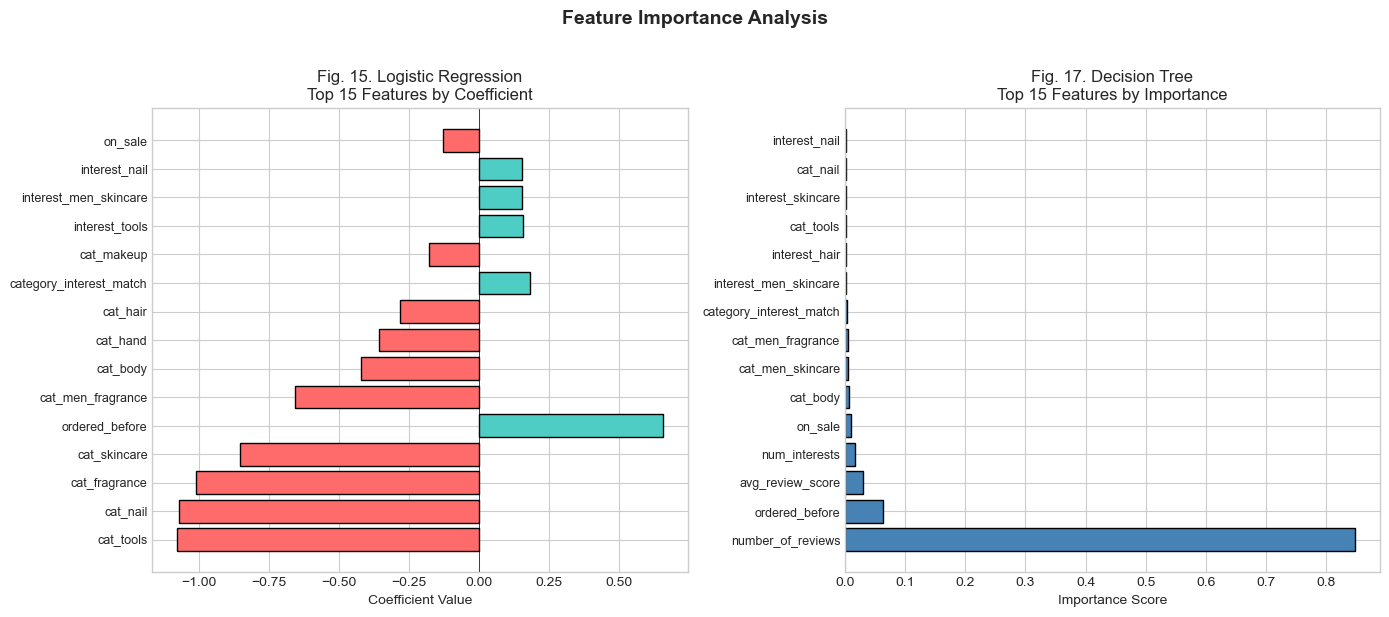

In [252]:
fig.suptitle('Feature Importance Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()